# 02. Authenticity: detecting edited / composited fire images
Block-8 CLIP features vs final-layer features vs non-learned forensic cues, with a held-out edit type and degradations. Results come from `docs/data/authenticity_*.json` (scripts `eval_authenticity.py`, `eval_authenticity_control.py`, `handcrafted_baseline.py`).

**Caveat:** the edits are crude splices built from D-Fire; realistic inpainting would be harder.

In [1]:
import json, os, sys, pathlib
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
ROOT = pathlib.Path(os.getcwd()).resolve().parent if pathlib.Path(os.getcwd()).name == "notebooks" else pathlib.Path(os.getcwd())
sys.path.insert(0, str(ROOT / "src"))
J = lambda n: json.load(open(ROOT / "docs" / "data" / n))
COL = {"blue": "#2f6fb3", "orange": "#d9822b", "grey": "#8a8f98", "green": "#3a9a6e", "red": "#c24d4d"}

## What the edits look like
Top: original. Bottom: edited (`paste_flames`, `paste_smoke`, `cover_region`).

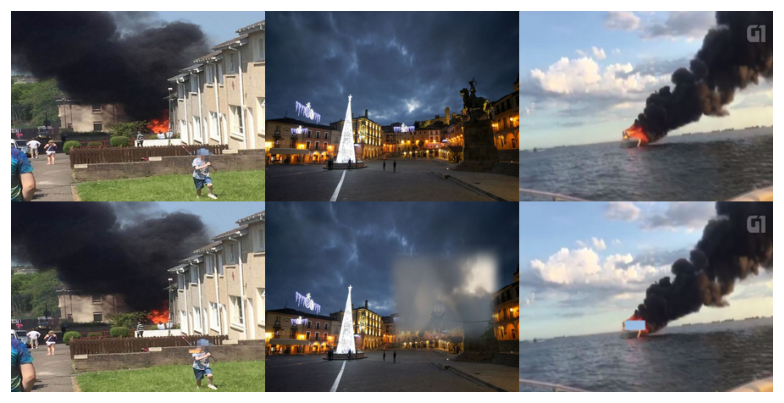

In [2]:
from PIL import Image
plt.figure(figsize=(10, 4.5)); plt.imshow(Image.open(ROOT / "docs/figures/edit_examples.png")); plt.axis("off"); plt.show()

## AUC on the test partition (95% CI, resampling whole clusters)

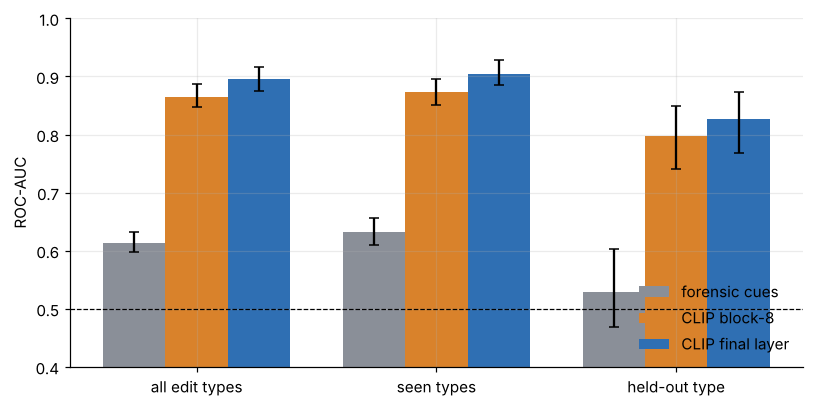

In [3]:
a, h = J("authenticity_edit_baseline.json"), J("authenticity_handcrafted_baseline.json")
rows = [("forensic cues", h["test_all"], h["test_seen_types"], h["test_cover_region_vs_neg"])]
for key, nm in (("block8_cls", "CLIP block-8"), ("final_embedding", "CLIP final layer")):
    r, r2 = a[key + "__train_all_types"], a[key + "__train_without_cover_region"]
    rows.append((nm, r["test_all_types"], r["test_seen_types"], r2["test_heldout_type"]))
groups = ["all edit types", "seen types", "held-out type"]; cols = [COL["grey"], COL["orange"], COL["blue"]]
fig, ax = plt.subplots(figsize=(7.5, 3.8)); w = .26
for i, (nm, *rr) in enumerate(rows):
    v = np.array([q["auc"] for q in rr]); ci = np.array([q.get("auc_ci95", q.get("ci95")) for q in rr])
    ax.bar(np.arange(3) + (i - 1) * w, v, w, yerr=[v - ci[:, 0], ci[:, 1] - v], capsize=3, color=cols[i], label=nm)
ax.axhline(.5, color="k", lw=.8, ls="--"); ax.set_xticks(range(3), groups); ax.set_ylim(.4, 1); ax.set_ylabel("ROC-AUC"); ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

## Degradation: edits caught at a fixed 5% false-flag rate
The head is trained on clean images; the threshold comes from validation negatives.

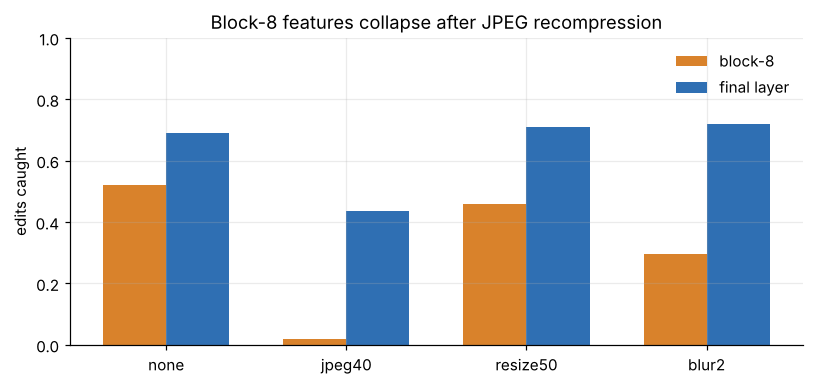

In [4]:
deg = ["none", "jpeg40", "resize50", "blur2"]; fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (key, nm, c) in enumerate((("block8_cls", "block-8", COL["orange"]), ("final_embedding", "final layer", COL["blue"]))):
    r = a[key + "__train_all_types"]; v = [r["test_all_types"]["tpr_at_val_thr"]] + [r[f"degraded_{d}"]["tpr_at_val_thr"] for d in deg[1:]]
    ax.bar(np.arange(4) + (i - .5) * .35, v, .35, color=c, label=nm)
ax.set_xticks(range(4), deg); ax.set_ylabel("edits caught"); ax.set_ylim(0, 1); ax.legend(frameon=False); ax.set_title("Block-8 features collapse after JPEG recompression"); plt.tight_layout(); plt.show()

## Shortcut check
Pasted edits always contain fire, so a detector could just be spotting fire. Restricting to fire-bearing base images:

In [5]:
c = J("authenticity_edit_control.json"); print("fire-bearing bases:", {k: round(v, 2) for k, v in c["base_fire_rate"].items()})
for k in ("block8_cls", "final_embedding"): print(k, "AUC %.3f  CI %s" % (c[k]["auc"], [round(x, 3) for x in c[k]["ci95"]]))

fire-bearing bases: {'negatives': 0.66, 'paste_positives': 0.67}
block8_cls AUC 0.868  CI [0.841, 0.896]
final_embedding AUC 0.898  CI [0.872, 0.925]


## Optional: re-run the head live from the cached features
Runs only if the CLIP feature files are present (not stored in the repo).

In [6]:
import csv
F = pathlib.Path(os.environ.get("TW_FEAT", "/home/user/data/feat")); E = pathlib.Path(os.environ.get("TW_EDITS", "/home/user/data/authenticity/edits_v1/edit_manifest.csv"))
if (F / "edits_clean.npz").exists() and E.exists():
    from fire_assessor.authenticity import AuthenticityHead
    from fire_assessor.metrics import roc_auc
    rows_ = list(csv.DictReader(open(E))); d = np.load(F / "edits_clean.npz"); y = np.array([int(r["edited_or_composited"]) for r in rows_]); part = np.array([r["partition"] for r in rows_])
    for key in ("block", "emb"):
        hd = AuthenticityHead.fit(d[key][part == "train"], y[part == "train", None].astype(float), l2=1e-2)
        print(key, "test AUC", round(roc_auc(y[part == "test"], hd.logits(d[key][part == "test"])[:, 0]), 3))
else: print("feature files not found; skipping live re-run")

block test AUC 0.865


emb test AUC 0.897
